# PROJECT 13: DỰ BÁO RỦI RO GIAO HÀNG CHẬM TRỄ TRONG CHUỖI CUNG ỨNG (DATACO)
## NOTEBOOK 01: KHÁM PHÁ VÀ KIỂM TOÁN CHẤT LƯỢNG DỮ LIỆU THÔ (DATA OVERVIEW)

**Mục tiêu nghiên cứu & học tập:**
- Làm quen và làm chủ quy trình khám phá dữ liệu thô (*Exploratory Data Analysis - EDA*) theo chuẩn CRISP-DM.
- Kiểm toán toàn diện chất lượng tệp dữ liệu thực hành cá nhân hóa `7_PJ13_2521001054_Nguyễn Lê Nhật Hạ.csv`.
- Phát hiện các vấn đề dữ liệu: giá trị khuyết (*Missing*), ký hiệu dơ (*Noise*), định dạng lỗi (*Invalid Format*), rò rỉ dữ liệu (*Data Leakage*) và vi phạm bảo mật (*PII*).
- Chuẩn bị cơ sở định lượng vững chắc để xây dựng quy tắc làm sạch cho bước kế tiếp (`02_data_cleaning.py`).

> **Nguyên tắc cốt lõi:** Tuyệt đối không chỉnh sửa, xóa hay ghi đè lên dữ liệu thô ban đầu trong notebook này. Chạy tuần tự từng cell để quan sát kết quả thực tế!

In [1]:
# CELL 2: Khởi tạo môi trường - Import các thư viện phân tích dữ liệu
import sys
import os
from pathlib import Path

# Đảm bảo mã hóa UTF-8 an toàn trên môi trường Windows
if sys.platform == 'win32':
    if hasattr(sys.stdout, 'reconfigure'):
        sys.stdout.reconfigure(encoding='utf-8')
    if hasattr(sys.stderr, 'reconfigure'):
        sys.stderr.reconfigure(encoding='utf-8')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

# Cấu hình font tiếng Việt và hiển thị biểu đồ
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', palette='Set2')

# Thiết lập hiển thị đầy đủ các cột của DataFrame
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)

print('-> Đã nạp thành công các thư viện: Pandas, NumPy, Matplotlib, Seaborn!')

-> Đã nạp thành công các thư viện: Pandas, NumPy, Matplotlib, Seaborn!


In [2]:
# CELL 3: Thiết lập đường dẫn file dữ liệu và kiểm tra sự tồn tại
raw_data_path = Path('data/raw/7_PJ13_2521001054_Nguyễn Lê Nhật Hạ.csv')

# Kiểm tra nếu file không có trong data/raw/ thì thử ở thư mục gốc
if not raw_data_path.exists():
    fallback_path = Path('7_PJ13_2521001054_Nguyễn Lê Nhật Hạ.csv')
    if fallback_path.exists():
        raw_data_path = fallback_path
        print(f'-> Đang sử dụng đường dẫn file tại thư mục gốc: {raw_data_path}')
    else:
        raise FileNotFoundError(f'[LỖI] Không tìm thấy file dữ liệu tại {raw_data_path}!')
else:
    print(f'-> [XÁC NHẬN] Đã tìm thấy file dữ liệu: {raw_data_path}')
    print(f'-> Dung lượng file: {os.path.getsize(raw_data_path) / (1024*1024):.2f} MB')

-> [XÁC NHẬN] Đã tìm thấy file dữ liệu: data\raw\7_PJ13_2521001054_Nguyễn Lê Nhật Hạ.csv
-> Dung lượng file: 83.20 MB


In [3]:
# CELL 4: Đọc file CSV gốc an toàn với encoding utf-8-sig
# Lưu ý: Đọc dtype='string' để bảo toàn trọn vẹn mọi ký hiệu dơ ban đầu (VND, ?, -, 9999...)
try:
    df = pd.read_csv(raw_data_path, encoding='utf-8-sig', low_memory=False, dtype='string')
    print(f'-> [THÀNH CÔNG] Đã nạp dữ liệu vào DataFrame!')
    print(f'-> Kích thước ban đầu: {df.shape[0]:,} dòng x {df.shape[1]} cột')
except UnicodeDecodeError:
    print('-> Thử lại với encoding latin1...')
    df = pd.read_csv(raw_data_path, encoding='latin1', low_memory=False, dtype='string')

-> [THÀNH CÔNG] Đã nạp dữ liệu vào DataFrame!
-> Kích thước ban đầu: 180,519 dòng x 53 cột


In [4]:
# CELL 5: Hiển thị 5 dòng đầu và 5 dòng cuối (ĐÃ ẨN DANH HÓA THÔNG TIN PII ĐỂ BẢO VỆ QUYỀN RIÊNG TƯ)
PII_COLS = ['Customer Email', 'Customer Password', 'Customer Fname', 'Customer Lname', 'Customer Street']

# Tạo bản sao an toàn để hiển thị trên màn hình
df_safe_display = df.copy()
for col in PII_COLS:
    if col in df_safe_display.columns:
        df_safe_display[col] = '***MASKED_PII***'

print('--- 5 DÒNG ĐẦU TIÊN (HEAD) ---')
display(df_safe_display.head())

print('--- 5 DÒNG CUỐI CÙNG (TAIL) ---')
display(df_safe_display.tail())

print(f'-> Tổng số cột trong bảng: {len(df.columns)}')
print('Danh sách các cột:', list(df.columns))

--- 5 DÒNG ĐẦU TIÊN (HEAD) ---


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,unknown,3,4,91.25,314.6400146,chưa rõ,0,73,chưa rõ,CAGUAS,PUERTO RICO,***MASKED_PII***,***MASKED_PII***,?,***MASKED_PII***,***MASKED_PII***,Consumer,PR,***MASKED_PII***,725,2,Fitness,18.2514534,-66.03705597,Pacific Asia,bekasi,Indonesia,-,1/31/2018 22:56,77202,1360,13.10999966,0.039999999,180517,<NA>,2.9,1,327.75,314.6400146,-,SOUTHEAST ASIA,java occidental,COMPLETE,<NA>,1360,<NA>,<NA>,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.0899963,311.3599854,Late delivery,<NA>,73,Sporting Goods,Caguas,Puerto Ri,***MASKED_PII***,***MASKED_PII***,<NA>,***MASKED_PII***,***MASKED_PII***,Consumer,<NA>,***MASKED_PII***,725,2,Fitness,<NA>,-66.0370636,Pacific Asia,bikaner,<NA>,19492,1/13/2018 12:27,75939,1360,16.38999939,0.050000001 USD,179254,"327,75 kg",<NA>,1,<NA>,311.3599854,-249.0899963,South Asia,<NA>,PENDING,<NA>,1360,73,<NA>,http://images.acmesports.sports/Smart+watch,<NA>,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,<NA>,<NA>,309.7200012,SHIPPING ON TIME,0 %,73,Sporting Goods,San Jose,EE. UU.,***MASKED_PII***,***MASKED_PII***,<NA>,***MASKED_PII***,***MASKED_PII***,Consumer,<NA>,***MASKED_PII***,95125,2,Fitness,37.29223251,-121.881279 %,Pacific Asia,Bikaner,INDIA,19491,1/13/2018 12:06,75938,1360,18.03000069 kg,0.059999999,179253,<NA>,-0.800000012,1,327.75,30972.0,-247.7799988,South Asia,chưa rõ,CLOSED,<NA>,<NA>,73,?,http://images.acmesports.sports/Smart+watch,<NA>,327.75,0.0,-,Standard Class
3,chưa rõ,3,4,22.86000061,<NA>,<NA>,?,73 VND,<NA>,Los Angeles,EE. UU.,***MASKED_PII***,***MASKED_PII***,19490,***MASKED_PII***,***MASKED_PII***,Home Office,?,***MASKED_PII***,90027,2,Fitness,34.12594605,-118.2910156,Pacific Asia,?,Australia,19490,1/13/2018 11:45,75937,1360,22.94000053,0.07,179252 đ,327.75,0.079999998,1,327.75,304.8099976,22.86000061,<NA>,queensland,COMPLETE,<NA>,-,73,<NA>,unknown,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,<NA>,2,<NA>,<NA>,298.25,<NA>,0,73,Sporting Goods,<NA>,Puerto Ri,***MASKED_PII***,***MASKED_PII***,19489,***MASKED_PII***,***MASKED_PII***,chưa rõ,unknown,***MASKED_PII***,725,2 kg,Fitness,18.25376892,?,Pacific Asia,TOWNSVILLE,<NA>,9999,1/13/2018 11:24,75936,-1,29.5,0.090000004,179251,327.75,-1,-,327.75,298.25,134.2100067,<NA>,?,PENDING_PAYMENT,<NA>,1360,73,<NA>,<NA>,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


--- 5 DÒNG CUỐI CÙNG (TAIL) ---


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
180514,CASH,4,?,40,399.980011,Shipping on time,<NA>,45,?,chưa rõ,EE. UU.,***MASKED_PII***,***MASKED_PII***,1005,***MASKED_PII***,***MASKED_PII***,Home Office,NY,***MASKED_PII***,11207,7,Fan Shop,40.64093018,-73.94271088,Pacific Asia,chưa rõ,China,1005,1/16/2016 3:40,26043,1004,0,0,65177,399.980011,0.100000001,1,399.980011,399.980011,40 đ,Eastern Asia,shanghái,CLOSED,<NA>,1004,45,<NA>,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 3:40,Standard Class
180515,DEBIT,3,2,-613.7700195,395.980011,<NA>,1,45,<NA>,<NA>,ee. uu.,***MASKED_PII***,***MASKED_PII***,<NA>,***MASKED_PII***,***MASKED_PII***,Corporate,CA,***MASKED_PII***,93304,9999,Fan Shop,<NA>,-119.0186996,Pacific Asia,hirakata,<NA>,9141,1/16/2016 1:34,26037,1004,-,0.01,65161,399.980011,-1.549999952,1,<NA>,395.980011,-613.7700195,unknown,<NA>,COMPLETE,<NA>,<NA>,45,<NA>,<NA>,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/19/2016 1:34,Second Class
180516,TRANSFER,-,<NA>,<NA>,391.980011,late delivery,1,45,FISHING,unknown,EE. UU.,***MASKED_PII***,***MASKED_PII***,291,***MASKED_PII***,***MASKED_PII***,Corporate,CT,***MASKED_PII***,6010,7,Fan Shop,41.62995911 USD,-72.96715546,Pacific Asia,Adelaide,Australia,291,1/15/2016 21:00,26024,1004,8,0.02,65129,399.980011,0.360000014,1,399.980011,391.980011,141.1100006,Oceania,australia del sur,PENDING,<NA>,1004,45,<NA>,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,1/20/2016 21:00,Standard Class
180517,PAYMENT,3,<NA>,186.2299957,387.980011,Advance shipping,0,45,FISHING,caguas,Puerto Rico,***MASKED_PII***,***MASKED_PII***,2813,***MASKED_PII***,***MASKED_PII***,Consumer,PR,***MASKED_PII***,725,-,Fan Shop,18.2133503,"-66,37057495 %",Pacific Asia,<NA>,Australia,2813 kg,1/15/2016 20:18,26022,1004,-1,0.029999999,65126,399.980011,0.479999989,1,-,387.980011,<NA>,Oceania,Australia del Sur,PENDING_PAYMENT,<NA>,1004,45,nan kg,http://images.acmesports.sports/Field+%26+Stre...,FIELD & STREAM SPORTSMAN 16 GUN FIRE SAFE,399.980011,0,1/18/2016 20:18,Standard Class
180518,PAYMENT,4,4,168.9499969,383.980011,chưa rõ,0,45,fishing,Caguas,Puerto Rico,***MASKED_PII***,***MASKED_PII***,7547,***MASKED_PII***,***MASKED_PII***,Consumer,<NA>,***MASKED_PII***,725,7,Fan Shop,18.29038048,-66.3706131,Pacific Asia,Nagercoil,India,7547 %,1/15/2016 18:54,26018,1004,16,0.039999999,65113,399.980011,0.439999998,1,<NA>,383.980011,168.9499969,South Asia,TAMIL NADU,<NA>,<NA>,1004,45,<NA>,http://images.acmesports.sports/Field+%26+Stre...,Field & Stream Sportsman 16 Gun Fire Safe,399.980011,0,<NA>,Standard Class


-> Tổng số cột trong bảng: 53
Danh sách các cột: ['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product P

### ĐÁNH GIÁ PHẦN 1: KHỞI TẠO VÀ ĐỌC DỮ LIỆU BAN ĐẦU

**A. Kết quả cần quan sát:**
- File có được đọc thành công không? Encoding nào được áp dụng?
- Các giá trị trong 5 dòng đầu và 5 dòng cuối có xuất hiện các ký tự lạ, lỗi font (`chÆ°a rÃµ`) hay đơn vị tiền tệ (`VND`, `USD`) lẫn vào không?
- Thông tin nhạy cảm PII (`Customer Email`, `Customer Password`, v.v.) đã được che giấu trong phần hiển thị chưa?

**B. Cách diễn giải:**
- Bộ dữ liệu DataCo là dữ liệu giao dịch bán lẻ đa kênh toàn cầu. Khi thu thập từ nhiều nguồn chi nhánh khác nhau qua các hệ thống ERP/TMS, dữ liệu thường bị lẫn đơn vị tiền tệ địa phương và lỗi font mã hóa.
- Việc đọc dữ liệu dạng chuỗi (`string`) ở bước đầu tiên giúp bảo toàn nguyên trạng mọi ký tự để chúng ta kiểm toán trước khi ép kiểu số học.

**C. Nhận xét sau khi chạy:**
> *(Sinh viên tự ghi nhận xét sau khi quan sát output từ Cell 1 đến Cell 5:)*  
> - Trạng thái đọc file: ...  
> - Ký hiệu lạ sơ bộ quan sát được ở các dòng đầu: ...  
> - Nhận xét về tính an toàn hiển thị PII: ...  

**D. Quyết định cho bước làm sạch:**
- Cần lập danh sách toàn bộ các ký hiệu tiền tệ/khối lượng/tỷ lệ để bóc tách bằng biểu thức chính quy (Regex).
- Cần lên kế hoạch loại bỏ hoàn toàn các cột PII ở pipeline làm sạch để tuân thủ quy định bảo mật GDPR.

In [5]:
# CELL 6: Kiểm tra df.shape, số dòng và số cột, đối chiếu với Schema chuẩn DataCo
EXPECTED_ROWS = 180519
EXPECTED_COLS = 53

n_rows, n_cols = df.shape
print(f'-> Kích thước thực tế: {n_rows:,} dòng x {n_cols} cột')
print(f'-> Kích thước chuẩn:   {EXPECTED_ROWS:,} dòng x {EXPECTED_COLS} cột')

if n_rows == EXPECTED_ROWS and n_cols == EXPECTED_COLS:
    print('=> [KẾT LUẬN] Kích thước dữ liệu KHỚP HOÀN TOÀN với chuẩn DataCo Supply Chain!')
else:
    print('=> [CẢNH BÁO] Có sự sai lệch kích thước so với bộ chuẩn DataCo!')

-> Kích thước thực tế: 180,519 dòng x 53 cột
-> Kích thước chuẩn:   180,519 dòng x 53 cột
=> [KẾT LUẬN] Kích thước dữ liệu KHỚP HOÀN TOÀN với chuẩn DataCo Supply Chain!


In [6]:
# CELL 7: Kiểm tra tổng quan df.info()
print('--- THÔNG TIN TỔNG QUAN TỪ DF.INFO() ---')
df.info(verbose=True, show_counts=True)

--- THÔNG TIN TỔNG QUAN TỪ DF.INFO() ---
<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype 
---  ------                         --------------   ----- 
 0   Type                           143211 non-null  string
 1   Days for shipping (real)       166975 non-null  string
 2   Days for shipment (scheduled)  149359 non-null  string
 3   Benefit per order              153670 non-null  string
 4   Sales per customer             168965 non-null  string
 5   Delivery Status                140068 non-null  string
 6   Late_delivery_risk             172141 non-null  string
 7   Category Id                    170282 non-null  string
 8   Category Name                  136175 non-null  string
 9   Customer City                  156196 non-null  string
 10  Customer Country               166059 non-null  string
 11  Customer Email                 170706 non-null  string
 12  Customer Fname

In [7]:
# CELL 8: Kiểm tra df.dtypes
print('--- DANH SÁCH KIỂU DỮ LIỆU CỦA 53 CỘT ---')
display(pd.DataFrame({'Tên Cột': df.columns, 'Kiểu Dữ Liệu Ban Đầu': df.dtypes.astype(str)}))

--- DANH SÁCH KIỂU DỮ LIỆU CỦA 53 CỘT ---


,Tên Cột,Kiểu Dữ Liệu Ban Đầu
Type,Type,string
Days for shipping (real),Days for shipping (real),string
Days for shipment (scheduled),Days for shipment (scheduled),string
Benefit per order,Benefit per order,string
Sales per customer,Sales per customer,string
Delivery Status,Delivery Status,string
Late_delivery_risk,Late_delivery_risk,string
Category Id,Category Id,string
Category Name,Category Name,string
Customer City,Customer City,string


In [8]:
# CELL 9: Thống kê số lượng cột theo nhóm kiểu dữ liệu
dtype_summary = df.dtypes.astype(str).value_counts().reset_index()
dtype_summary.columns = ['Kiểu Dữ Liệu', 'Số Lượng Cột']
print('--- THỐNG KÊ SỐ LƯỢNG CỘT THEO DTYPE ---')
display(dtype_summary)

--- THỐNG KÊ SỐ LƯỢNG CỘT THEO DTYPE ---


,Kiểu Dữ Liệu,Số Lượng Cột
0,string,53


In [9]:
# CELL 10: Thống kê mô tả tổng quát bằng df.describe()
print('--- THỐNG KÊ MÔ TẢ TỔNG QUÁT (TẤT CẢ CÁC CỘT) ---')
# Chỉ lấy mẫu các thông số chính: count, unique, top, freq để tránh tràn màn hình
desc_summary = df.describe().T
display(desc_summary.head(25))
display(desc_summary.tail(28))

--- THỐNG KÊ MÔ TẢ TỔNG QUÁT (TẤT CẢ CÁC CỘT) ---


,count,unique,top,freq
Type,143211,18,DEBIT,26711
Days for shipping (real),166975,9,2,50615
Days for shipment (scheduled),149359,6,4,81709
Benefit per order,153670,29519,-,6666
Sales per customer,168965,8910,-,2931
Delivery Status,140068,22,Late delivery,25319
Late_delivery_risk,172141,22,1,82379
Category Id,170282,474,17,18659
Category Name,136175,251,chưa rõ,8949
Customer City,156196,2810,Caguas,24822


,count,unique,top,freq
Order City,138619,14559,chưa rõ,8373
Order Country,140096,745,chưa rõ,8188
Order Customer Id,164318,32426,-,4121
order date (DateOrders),165401,63243,?,3047
Order Id,165353,73463,-,3805
Order Item Cardprod Id,174847,932,365,19258
Order Item Discount,150476,4211,-1,7630
Order Item Discount Rate,168087,263,0.039999999,7726
Order Item Id,171195,162000,?,2389
Order Item Product Price,158303,697,59.99000168,16888


In [10]:
# CELL 11: Thống kê mô tả các biến phân loại
print('--- THỐNG KÊ MÔ TẢ CÁC BIẾN PHÂN LOẠI (OBJECT/STRING) ---')
# Thống kê số lượng giá trị duy nhất (cardinality) của từng cột
cardinality_df = pd.DataFrame({
    'Tên Cột': df.columns,
    'Số Giá Trị Khác Nhau (Unique)': [df[c].nunique(dropna=True) for c in df.columns],
    'Giá Trị Xuất Hiện Nhiều Nhất (Top)': [df[c].mode().iloc[0] if len(df[c].mode())>0 else 'NA' for c in df.columns],
    'Tần Suất Top (Freq)': [df[c].value_counts().iloc[0] if len(df[c].value_counts())>0 else 0 for c in df.columns]
})
display(cardinality_df.sort_values(by='Số Giá Trị Khác Nhau (Unique)', ascending=False))

--- THỐNG KÊ MÔ TẢ CÁC BIẾN PHÂN LOẠI (OBJECT/STRING) ---


,Tên Cột,Số Giá Trị Khác Nhau (Unique),Giá Trị Xuất Hiện Nhiều Nhất (Top),Tần Suất Top (Freq)
33,Order Item Id,162000,?,2389
29,Order Id,73463,-,3805
28,order date (DateOrders),63243,?,3047
51,shipping date (DateOrders),60695,?,3699
13,Customer Id,34516,9999,5226
39,Order Profit Per Order,34418,9999,1121
27,Order Customer Id,32426,-,4121
18,Customer Street,30503,unknown,7649
3,Benefit per order,29519,-,6666
22,Latitude,27237,9999,3808


### CHECKPOINT 1: CẤU TRÚC DỮ LIỆU & SCHEMA

**A. Kết quả cần quan sát:**
- Số lượng dòng có đúng 180.519 và số lượng cột có đúng 53 cột không?
- Toàn bộ các cột đang ở dạng `string` hay đã có cột nào được nhận diện là số/ngày tháng?
- Cột nào có số lượng giá trị độc nhất (*Cardinality*) cực cao (như ID, tên khách hàng) và cột nào có Cardinality thấp (như Shipping Mode, Customer Segment)?

**B. Cách diễn giải:**
- Khi đọc dữ liệu bằng Pandas mà chưa ép kiểu, các cột chứa số bị lẫn chữ/đơn vị tiền tệ sẽ tự động bị ép thành `string/object`. Đây là biểu hiện tự nhiên của dữ liệu thô chưa qua làm sạch.
- Bộ nhớ RAM hiện tại tiêu tốn khá lớn do toàn bộ đều là chuỗi ký tự.

**C. Nhận xét sau khi chạy:**
> *(Sinh viên tự ghi nhận xét sau khi quan sát output từ Cell 6 đến Cell 11:)*  
> - Kích thước dữ liệu: ... dòng x ... cột (Có khớp chuẩn DataCo không: ...)  
> - Nhận xét về kiểu dữ liệu ban đầu: ...  
> - Cột có Cardinality cao nhất / thấp nhất: ...  

**D. Quyết định cho bước làm sạch:**
- Cần chuyển đổi kiểu dữ liệu tối ưu: số nguyên nhỏ (`int8`, `int32`), số thực (`float32`), chuỗi lặp lại sang `category` để tiết kiệm RAM (>70%).
- Cần chuyển đổi các trường ngày tháng (`order date`, `shipping date`) sang định dạng chuẩn `datetime64`.

In [11]:
# CELL 12: Đếm số lượng giá trị NaN tiêu chuẩn theo từng cột
null_counts = df.isna().sum()
null_df = pd.DataFrame({
    'Tên Cột': df.columns,
    'Số Lượng NaN': null_counts.values
}).sort_values(by='Số Lượng NaN', ascending=False)

print('--- TOP CỘT CÓ SỐ LƯỢNG GIÁ TRỊ KHUYẾT (NAN) CAO NHẤT ---')
display(null_df.head(15))

--- TOP CỘT CÓ SỐ LƯỢNG GIÁ TRỊ KHUYẾT (NAN) CAO NHẤT ---


,Tên Cột,Số Lượng NaN
46,Product Description,150661
43,Order Zipcode,143152
41,Order State,44944
8,Category Name,44344
25,Order City,41900
5,Delivery Status,40451
26,Order Country,40423
18,Customer Street,38147
0,Type,37308
2,Days for shipment (scheduled),31160


In [12]:
# CELL 13: Tính tỷ lệ phần trăm (%) NaN theo từng cột và trên toàn bộ dữ liệu
total_cells = df.shape[0] * df.shape[1]
total_nulls = df.isna().sum().sum()

null_df['Tỷ Lệ NaN (%)'] = (null_df['Số Lượng NaN'] / len(df)) * 100
null_df['Tỷ Lệ NaN (%)'] = null_df['Tỷ Lệ NaN (%)'].round(2)

print(f'-> Tổng số ô trong bảng dữ liệu: {total_cells:,} ô')
print(f'-> Tổng số ô bị khuyết NaN:       {total_nulls:,} ô ({total_nulls / total_cells * 100:.2f}%)')
print('\n--- BẢNG TỶ LỆ KHUYẾT THEO CỘT ---')
display(null_df.head(20))

-> Tổng số ô trong bảng dữ liệu: 9,567,507 ô
-> Tổng số ô bị khuyết NaN:       1,245,685 ô (13.02%)

--- BẢNG TỶ LỆ KHUYẾT THEO CỘT ---


,Tên Cột,Số Lượng NaN,Tỷ Lệ NaN (%)
46,Product Description,150661,83.46
43,Order Zipcode,143152,79.30
41,Order State,44944,24.90
8,Category Name,44344,24.56
25,Order City,41900,23.21
5,Delivery Status,40451,22.41
26,Order Country,40423,22.39
18,Customer Street,38147,21.13
0,Type,37308,20.67
2,Days for shipment (scheduled),31160,17.26


In [13]:
# CELL 14: Kiểm tra và thống kê các ký hiệu thiếu / nhiễu ẩn danh (?, -, nan, None, unknown, -1, 9999...)
SUSPICIOUS_LIST = ['?', '-', 'nan', 'none', 'unknown', '-1', '9999', 'chæ°a rãµ', 'chưa rõ']

suspicious_results = {}
for sym in SUSPICIOUS_LIST:
    # Đếm số lần xuất hiện của ký hiệu này trên toàn bộ DataFrame
    cnt = 0
    for col in df.columns:
        s = df[col].astype('string').str.strip().str.lower()
        cnt += int(s.eq(sym).sum())
    suspicious_results[sym] = cnt

suspicious_summary_df = pd.DataFrame(list(suspicious_results.items()), columns=['Ký Hiệu Nhiễu', 'Số Lần Xuất Hiện'])
print('--- THỐNG KÊ CÁC KÝ HIỆU NHIỄU / KHUYẾT ẨN TRÊN TOÀN BỘ DATASET ---')
display(suspicious_summary_df.sort_values(by='Số Lần Xuất Hiện', ascending=False))

--- THỐNG KÊ CÁC KÝ HIỆU NHIỄU / KHUYẾT ẨN TRÊN TOÀN BỘ DATASET ---


,Ký Hiệu Nhiễu,Số Lần Xuất Hiện
0,?,210700
1,-,110853
8,chưa rõ,100938
4,unknown,100148
6,9999,94674
5,-1,94625
2,nan,12531
3,none,0
7,chæ°a rãµ,0


In [14]:
# CELL 15: Thống kê số lượng và tỷ lệ ký hiệu thiếu theo từng cột (KHÔNG LÀM LỘ GIÁ TRỊ PII)
col_noise_records = []

for col in df.columns:
    s = df[col].astype('string').str.strip().str.lower()
    nan_cnt = int(df[col].isna().sum())
    q_cnt = int(s.eq('?').sum())
    dash_cnt = int(s.eq('-').sum())
    unk_cnt = int(s.isin(['unknown', 'chưa rõ', 'chæ°a rãµ']).sum())
    neg_cnt = int(s.eq('-1').sum())
    num9_cnt = int(s.eq('9999').sum())
    
    total_bad = nan_cnt + q_cnt + dash_cnt + unk_cnt + neg_cnt + num9_cnt
    col_noise_records.append({
        'Tên Cột': col,
        'Số NaN': nan_cnt,
        'Ký hiệu ?': q_cnt,
        'Ký hiệu -': dash_cnt,
        'unknown / chưa rõ': unk_cnt,
        '-1 hoặc 9999': neg_cnt + num9_cnt,
        'Tổng Dữ Liệu Dơ': total_bad,
        'Tỷ Lệ Dơ Tổng (%)': round((total_bad / len(df)) * 100, 2)
    })

noise_report_df = pd.DataFrame(col_noise_records).sort_values(by='Tỷ Lệ Dơ Tổng (%)', ascending=False)
print('--- BẢNG KIỂM TOÁN TỔNG HỢP GIÁ TRỊ THIẾU VÀ NHIỄU THEO TỪNG CỘT ---')
display(noise_report_df.head(20))

--- BẢNG KIỂM TOÁN TỔNG HỢP GIÁ TRỊ THIẾU VÀ NHIỄU THEO TỪNG CỘT ---


,Tên Cột,Số NaN,Ký hiệu ?,Ký hiệu -,unknown / chưa rõ,-1 hoặc 9999,Tổng Dữ Liệu Dơ,Tỷ Lệ Dơ Tổng (%)
46,Product Description,150661,2478,2495,0,4936,160570,88.95
43,Order Zipcode,143152,0,0,0,0,143152,79.30
41,Order State,44944,9047,0,17857,0,71848,39.80
8,Category Name,44344,8875,0,17714,0,70933,39.29
25,Order City,41900,8319,0,16743,0,66962,37.09
5,Delivery Status,40451,8230,0,16252,0,64933,35.97
26,Order Country,40423,8145,0,16212,0,64780,35.89
18,Customer Street,38147,7625,0,15193,0,60965,33.77
31,Order Item Discount,30043,7507,7610,0,15159,60319,33.41
0,Type,37308,7394,0,14820,0,59522,32.97


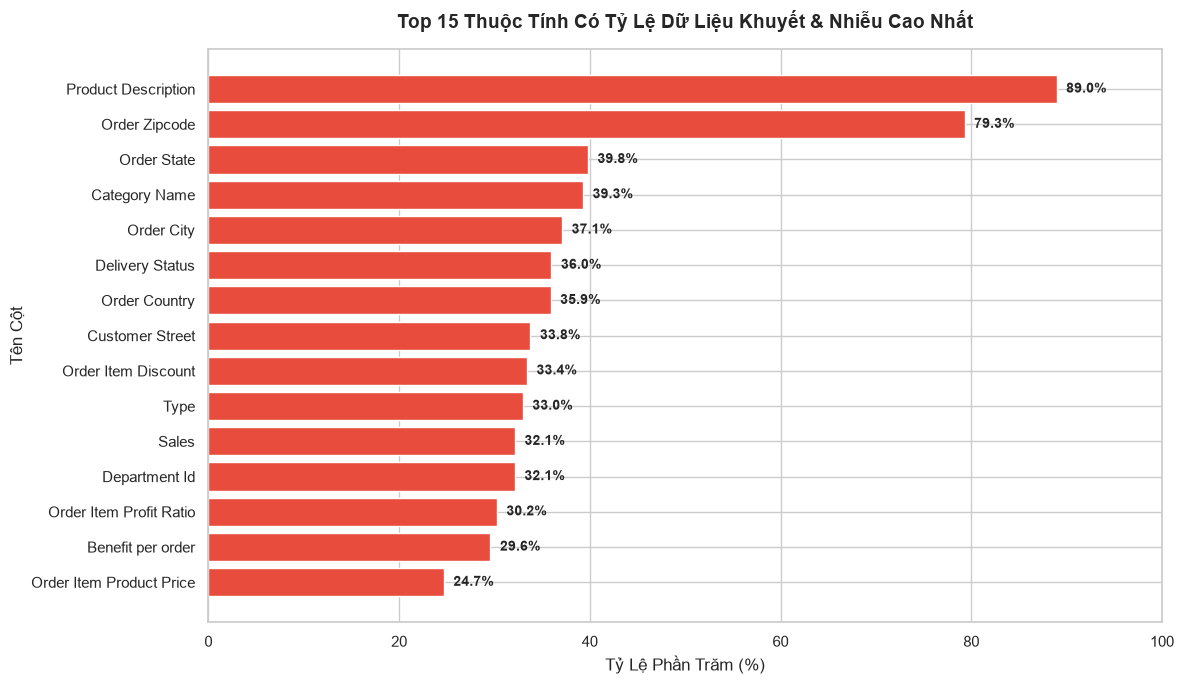

In [15]:
# CELL 16: Vẽ biểu đồ Top 15 cột có tỷ lệ dữ liệu thiếu và nhiễu cao nhất
plt.figure(figsize=(12, 7))
top_15_dirty = noise_report_df.head(15)

bars = plt.barh(top_15_dirty['Tên Cột'][::-1], top_15_dirty['Tỷ Lệ Dơ Tổng (%)'][::-1], color='#e74c3c')
plt.title('Top 15 Thuộc Tính Có Tỷ Lệ Dữ Liệu Khuyết & Nhiễu Cao Nhất', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Tỷ Lệ Phần Trăm (%)', fontsize=12)
plt.ylabel('Tên Cột', fontsize=12)
plt.xlim(0, 100)

# Hiển thị nhãn giá trị % trên từng cột
for bar in bars:
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### CHECKPOINT 2: DỮ LIỆU THIẾU VÀ NHIỄU

**A. Kết quả cần quan sát:**
- Những cột nào có tỷ lệ khuyết thiếu cực cao (>70%)?
- Ký hiệu nào xuất hiện phổ biến nhất trong các ký hiệu nghi vấn (`?`, `-`, `unknown`, `9999`)?
- Có trường hợp nào dữ liệu số bị ghi nhận thành `-1` hoặc `9999` để biểu thị giá trị thiếu không?

**B. Cách diễn giải:**
- Trong dữ liệu DataCo, các trường như `Product Description` và `Order Zipcode` thường có tỷ lệ khuyết $>75-80\%$. Đây là đặc trưng phổ biến do hệ thống cũ không lưu mô tả sản phẩm dạng text hoặc mã bưu chính đơn hàng quốc tế không được nhập.
- Các ký hiệu như `?`, `-`, `chưa rõ` là lỗi nhập liệu tự do từ người dùng hoặc hệ thống giao diện.

**C. Nhận xét sau khi chạy:**
> *(Sinh viên tự ghi nhận xét sau khi quan sát output từ Cell 12 đến Cell 16:)*  
> - Cột khuyết nhiều nhất: ... (tỷ lệ: ...%)  
> - Ký hiệu nhiễu xuất hiện nhiều nhất: ...  
> - Những cột quan trọng (Target, Shipping Mode) có bị khuyết không: ...  

**D. Quyết định cho bước làm sạch:**
- Với các cột khuyết quá lớn (>70% như `Product Description`, `Order Zipcode`): Cân nhắc loại bỏ vì không cung cấp đủ thông tin giá trị cho mô hình.
- Với các cột danh mục có khuyết thiếu: Điền giá trị an toàn `'Unknown'` thay vì xóa bỏ dòng.
- Với các cột số ngày vận chuyển hoặc tài chính: Tuyệt đối không xóa dòng; điền khuyết bằng `median` theo phân nhóm (`Shipping Mode` hoặc `Category Name`).

In [16]:
# CELL 18: Đếm số dòng trùng lặp 100% hoàn toàn trên tất cả các cột
exact_dups = int(df.duplicated().sum())
print(f'-> Số lượng dòng trùng lặp hoàn toàn (100% tất cả các cột): {exact_dups:,} dòng')
if exact_dups == 0:
    print('=> [XÁC NHẬN] Tập dữ liệu không chứa bất kỳ bản ghi nào trùng lặp 100%!')
else:
    print(f'=> [LƯU Ý] Có {exact_dups} dòng trùng lặp hoàn toàn cần xử lý drop_duplicates!')

-> Số lượng dòng trùng lặp hoàn toàn (100% tất cả các cột): 0 dòng
=> [XÁC NHẬN] Tập dữ liệu không chứa bất kỳ bản ghi nào trùng lặp 100%!


In [17]:
# CELL 19: Đếm số lượng Order Id duy nhất và số lần xuất hiện lặp lại
if 'Order Id' in df.columns:
    order_id_unique = df['Order Id'].nunique(dropna=True)
    order_id_dups = df['Order Id'].duplicated().sum()
    print(f'-> Số lượng Order Id duy nhất:     {order_id_unique:,} mã đơn hàng')
    print(f'-> Số dòng lặp lại của Order Id:   {order_id_dups:,} dòng')
    print(f'-> Trung bình mỗi Order Id xuất hiện: {len(df) / order_id_unique:.2f} dòng')

-> Số lượng Order Id duy nhất:     73,463 mã đơn hàng
-> Số dòng lặp lại của Order Id:   107,055 dòng
-> Trung bình mỗi Order Id xuất hiện: 2.46 dòng


In [18]:
# CELL 20: Kiểm tra số dòng trùng Order Item Id (Khóa chính kỹ thuật)
if 'Order Item Id' in df.columns:
    item_id_unique = df['Order Item Id'].nunique(dropna=True)
    item_id_dups = df['Order Item Id'].duplicated().sum()
    print(f'-> Số lượng Order Item Id duy nhất:   {item_id_unique:,} mã mục hàng')
    print(f'-> Số dòng trùng của Order Item Id: {item_id_dups:,} dòng')
    if item_id_dups > 0:
        print('=> [CẢNH BÁO] Phát hiện mã Order Item Id bị lặp lại, cần kiểm tra nguyên nhân!')

-> Số lượng Order Item Id duy nhất:   162,000 mã mục hàng
-> Số dòng trùng của Order Item Id: 18,518 dòng
=> [CẢNH BÁO] Phát hiện mã Order Item Id bị lặp lại, cần kiểm tra nguyên nhân!


In [19]:
# CELL 21: Phân tích số dòng chi tiết sản phẩm (Order Items) trong mỗi đơn hàng
if 'Order Id' in df.columns:
    items_per_order = df.groupby('Order Id').size()
    print('--- PHÂN BỐ SỐ MỤC HÀNG TRÊN MỖI ĐƠN HÀNG ---')
    display(items_per_order.value_counts().reset_index().rename(
        columns={'index': 'Số Sản Phẩm Trong Đơn', 'count': 'Số Lượng Đơn Hàng'}
    ).head(10))

--- PHÂN BỐ SỐ MỤC HÀNG TRÊN MỖI ĐƠN HÀNG ---


,Số Sản Phẩm Trong Đơn,Số Lượng Đơn Hàng
0,1,34608
1,2,14799
2,3,12794
3,4,8382
4,5,2876
5,3805,1
6,3684,1
7,3734,1
8,3634,1


### CHECKPOINT 3: TRÙNG LẶP & ĐƠN VỊ QUAN SÁT (UNIT OF ANALYSIS)

**A. Kết quả cần quan sát:**
- Có bao nhiêu dòng trùng hoàn toàn 100%?
- Có bao nhiêu `Order Id` duy nhất? Tỷ lệ đơn hàng có nhiều hơn 1 mục hàng là bao nhiêu?
- Khóa `Order Item Id` có bị trùng lặp không?

**B. Cách diễn giải nghiệp vụ:**
- **Tại sao trùng `Order Id` KHÔNG phải là lỗi dữ liệu?**  
  Trong thương mại điện tử và bán lẻ, một đơn hàng (`Order Id`) thường bao gồm nhiều sản phẩm khác nhau (`Order Items`). Mỗi dòng trong tệp DataCo biểu diễn một mục hàng cụ thể. Do đó, việc `Order Id` xuất hiện lặp lại 2, 3 hay 5 lần là hoàn toàn tự nhiên và đúng với cấu trúc quan hệ bảng 1-nhiều (*One-to-Many Relationship*).
- Nếu xóa bỏ các dòng trùng `Order Id`, chúng ta sẽ vô tình làm mất toàn bộ thông tin về các mặt hàng con trong đơn hàng!

**C. Nhận xét sau khi chạy:**
> *(Sinh viên tự ghi nhận xét sau khi quan sát output từ Cell 18 đến Cell 21:)*  
> - Số dòng trùng lặp 100%: ...  
> - Số lượng Order Id duy nhất: ...  
> - Nhận xét về việc phân bổ số mục hàng trên mỗi đơn: ...  

**D. Quyết định cho bước làm sạch:**
- Chỉ thực hiện loại bỏ trùng lặp hoàn toàn (`df.drop_duplicates()`), tuyệt đối không được drop duplicates chỉ dựa trên cột `Order Id`.

In [20]:
# CELL 23: Kiểm tra các giá trị thô gốc của biến mục tiêu Late_delivery_risk
if 'Late_delivery_risk' in df.columns:
    raw_target_counts = df['Late_delivery_risk'].value_counts(dropna=False)
    print('--- TẤT CẢ CÁC GIÁ TRỊ GỐC XUẤT HIỆN TRONG LATE_DELIVERY_RISK ---')
    display(raw_target_counts.reset_index().rename(
        columns={'Late_delivery_risk': 'Giá Trị Gốc', 'count': 'Số Lượng Dòng'}
    ))

--- TẤT CẢ CÁC GIÁ TRỊ GỐC XUẤT HIỆN TRONG LATE_DELIVERY_RISK ---


,Giá Trị Gốc,Số Lượng Dòng
0,1,82379
1,0,67946
2,<NA>,8378
3,?,2180
4,9999,2145
5,-,2063
6,-1,2033
7,0.0,1474
8,1 VND,1039
9,1 USD,1026


In [21]:
# CELL 24: Đếm số lượng nhãn hợp lệ (0, 1) và các nhãn không hợp lệ (nhiễu)
if 'Late_delivery_risk' in df.columns:
    target_clean_str = df['Late_delivery_risk'].astype('string').str.strip()
    n_valid_0 = int(target_clean_str.eq('0').sum())
    n_valid_1 = int(target_clean_str.eq('1').sum())
    n_missing = int(target_clean_str.isna().sum())
    n_invalid = len(df) - (n_valid_0 + n_valid_1 + n_missing)
    
    target_audit_df = pd.DataFrame([
        {'Phân Loại Nhãn': 'Nhãn 0 Hợp Lệ (Đúng hạn / Sớm)', 'Số Lượng': n_valid_0, 'Tỷ Lệ (%)': round(n_valid_0 / len(df) * 100, 2)},
        {'Phân Loại Nhãn': 'Nhãn 1 Hợp Lệ (Trễ hạn)', 'Số Lượng': n_valid_1, 'Tỷ Lệ (%)': round(n_valid_1 / len(df) * 100, 2)},
        {'Phân Loại Nhãn': 'Nhãn Khuyết (NaN)', 'Số Lượng': n_missing, 'Tỷ Lệ (%)': round(n_missing / len(df) * 100, 2)},
        {'Phân Loại Nhãn': 'Nhãn Nhiễu Chuỗi (VND, USD, ?, -1...)', 'Số Lượng': n_invalid, 'Tỷ Lệ (%)': round(n_invalid / len(df) * 100, 2)}
    ])
    print('--- BẢNG THỐNG KÊ PHÂN LOẠI NHÃN MỤC TIÊU ---')
    display(target_audit_df)

--- BẢNG THỐNG KÊ PHÂN LOẠI NHÃN MỤC TIÊU ---


,Phân Loại Nhãn,Số Lượng,Tỷ Lệ (%)
0,Nhãn 0 Hợp Lệ (Đúng hạn / Sớm),67946,37.64
1,Nhãn 1 Hợp Lệ (Trễ hạn),82379,45.63
2,Nhãn Khuyết (NaN),8378,4.64
3,"Nhãn Nhiễu Chuỗi (VND, USD, ?, -1...)",21816,12.09


In [22]:
# CELL 25: Tính tỷ lệ phần trăm giữa hai lớp hợp lệ (Class Distribution)
total_valid_labels = n_valid_0 + n_valid_1
pct_0 = (n_valid_0 / total_valid_labels) * 100
pct_1 = (n_valid_1 / total_valid_labels) * 100

print(f'-> Trong số {total_valid_labels:,} nhãn hợp lệ ban đầu:')
print(f'   + Lớp 0 (Đúng hạn): {n_valid_0:,} dòng ({pct_0:.2f}%)')
print(f'   + Lớp 1 (Trễ hạn):  {n_valid_1:,} dòng ({pct_1:.2f}%)')
print(f'-> Tỷ lệ mất cân bằng (Imbalance Ratio): {pct_1 / pct_0:.2f} : 1')
print('=> [ĐÁNH GIÁ] Tỷ lệ phân phối tương đối cân bằng tự nhiên, không rơi vào tình trạng mất cân bằng nghiêm trọng (Severe Imbalance).')

-> Trong số 150,325 nhãn hợp lệ ban đầu:
   + Lớp 0 (Đúng hạn): 67,946 dòng (45.20%)
   + Lớp 1 (Trễ hạn):  82,379 dòng (54.80%)
-> Tỷ lệ mất cân bằng (Imbalance Ratio): 1.21 : 1
=> [ĐÁNH GIÁ] Tỷ lệ phân phối tương đối cân bằng tự nhiên, không rơi vào tình trạng mất cân bằng nghiêm trọng (Severe Imbalance).


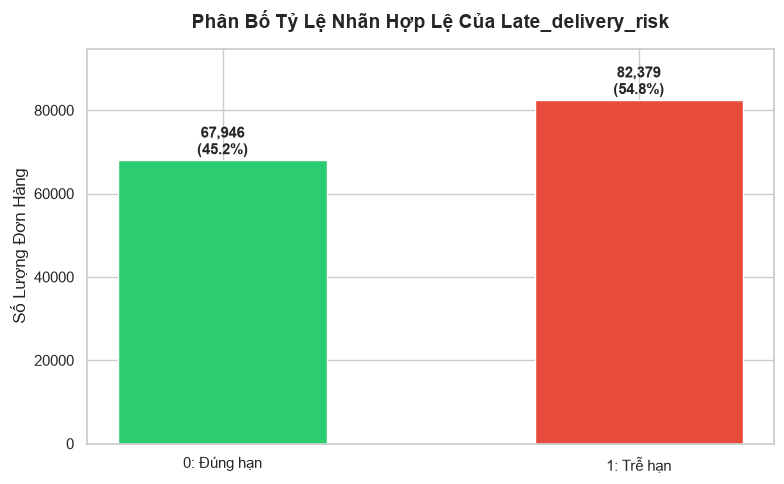

In [23]:
# CELL 26: Vẽ biểu đồ phân bố nhãn mục tiêu Late_delivery_risk
plt.figure(figsize=(8, 5))
bars = plt.bar(['0: Đúng hạn', '1: Trễ hạn'], [n_valid_0, n_valid_1], color=['#2ecc71', '#e74c3c'], width=0.5)
plt.title('Phân Bố Tỷ Lệ Nhãn Hợp Lệ Của Late_delivery_risk', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Số Lượng Đơn Hàng', fontsize=12)
plt.ylim(0, max(n_valid_0, n_valid_1) * 1.15)

for bar in bars:
    h = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, h + 1500, f'{h:,}\n({h/total_valid_labels*100:.1f}%)',
             ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

In [24]:
# CELL 27: Kiểm tra sơ bộ sự nhất quán giữa nhãn và hai cột số ngày giao hàng
# Lưu ý: Chỉ sử dụng các giá trị gốc hợp lệ, không sửa dữ liệu
real_days = pd.to_numeric(df['Days for shipping (real)'].str.extract(r'(\d+)')[0], errors='coerce')
sched_days = pd.to_numeric(df['Days for shipment (scheduled)'].str.extract(r'(\d+)')[0], errors='coerce')

# Logic SCM: Đơn hàng trễ hạn khi số ngày thực tế > số ngày cam kết
scm_late_flag = (real_days > sched_days).astype('Int8')
raw_target_num = pd.to_numeric(df['Late_delivery_risk'].str.extract(r'(\d+)')[0], errors='coerce').astype('Int8')

# Đếm số trường hợp xung đột logic giữa nhãn gốc và thời gian thực tế
valid_mask = scm_late_flag.notna() & raw_target_num.isin([0, 1])
matches = (scm_late_flag[valid_mask] == raw_target_num[valid_mask]).sum()
mismatches = (scm_late_flag[valid_mask] != raw_target_num[valid_mask]).sum()

print('--- KIỂM TRA ĐỐI CHIẾU LOGIC QUY TẮC VÀNG SCM ---')
print(f'-> Số dòng kiểm tra hợp lệ:           {valid_mask.sum():,} dòng')
print(f'-> Số dòng KHỚP logic (real > sched):  {matches:,} dòng ({matches / valid_mask.sum() * 100:.2f}%)')
print(f'-> Số dòng XUNG ĐỘT logic:             {mismatches:,} dòng ({mismatches / valid_mask.sum() * 100:.2f}%)')

--- KIỂM TRA ĐỐI CHIẾU LOGIC QUY TẮC VÀNG SCM ---
-> Số dòng kiểm tra hợp lệ:           111,206 dòng
-> Số dòng KHỚP logic (real > sched):  107,926 dòng (97.05%)
-> Số dòng XUNG ĐỘT logic:             3,280 dòng (2.95%)


### CHECKPOINT 4: KHÁM PHÁ BIẾN MỤC TIÊU (TARGET AUDIT)

**A. Kết quả cần quan sát:**
- Biến `Late_delivery_risk` có bao nhiêu nhãn 0, bao nhiêu nhãn 1 hợp lệ?
- Có bao nhiêu dòng bị dính đơn vị tiền tệ/khối lượng/ký hiệu lạ (`1 VND`, `1 USD`, `1 kg`, `?`, `9999`)?
- Khi đối chiếu với điều kiện `Days for shipping (real) > Days for shipment (scheduled)`, tỷ lệ khớp logic là bao nhiêu %?

**B. Cách diễn giải nghiệp vụ:**
- Trong bài toán SCM, biến mục tiêu `Late_delivery_risk` biểu thị rủi ro vi phạm cam kết SLA giao vận.
- Hiện tượng nhãn bị lẫn đơn vị tiền tệ (`1 VND`, `1 USD`) phát sinh do lỗi xuất nhập bảng trên hệ thống dữ liệu phân tán.
- Mối quan hệ giữa thời gian thực tế và cam kết chính là **Quy tắc Nghiệp vụ Vàng (Ground Truth)** giúp khôi phục toàn bộ các nhãn bị lỗi mà không cần phỏng đoán bừa bãi.

**C. Nhận xét sau khi chạy:**
> *(Sinh viên tự ghi nhận xét sau khi quan sát output từ Cell 23 đến Cell 27:)*  
> - Số lượng nhãn 0 vs 1 hợp lệ: ...  
> - Tỷ lệ khớp logic giữa nhãn và số ngày vận chuyển: ...%  
> - Nhận xét về tính cân bằng của biến mục tiêu: ...  

**D. Quyết định cho bước làm sạch:**
- Áp dụng Quy tắc Vàng SCM: `Late_delivery_risk = 1` nếu `real > scheduled`, ngược lại `0` kết hợp đối chiếu `Delivery Status` để khôi phục 100% nhãn sạch.

In [25]:
# CELL 28: Khảo sát phân bố của Phương thức vận chuyển (Shipping Mode)
if 'Shipping Mode' in df.columns:
    sm_counts = df['Shipping Mode'].value_counts(dropna=False).reset_index()
    sm_counts.columns = ['Shipping Mode', 'Số Lượng']
    sm_counts['Tỷ Lệ (%)'] = (sm_counts['Số Lượng'] / len(df) * 100).round(2)
    print('--- PHÂN BỐ PHƯƠNG THỨC VẬN CHUYỂN (SHIPPING MODE) ---')
    display(sm_counts.head(15))

--- PHÂN BỐ PHƯƠNG THỨC VẬN CHUYỂN (SHIPPING MODE) ---


,Shipping Mode,Số Lượng,Tỷ Lệ (%)
0,Standard Class,97743,54.15
1,Second Class,31560,17.48
2,First Class,24955,13.82
3,Same Day,8701,4.82
4,<NA>,5859,3.25
5,Standard Cla,1485,0.82
6,standard class,1463,0.81
7,STANDARD CLASS,1424,0.79
8,?,1176,0.65
9,unknown,1176,0.65


In [26]:
# CELL 29: Khảo sát phân bố Thị trường (Market)
if 'Market' in df.columns:
    market_counts = df['Market'].value_counts(dropna=False).reset_index()
    market_counts.columns = ['Market', 'Số Lượng']
    market_counts['Tỷ Lệ (%)'] = (market_counts['Số Lượng'] / len(df) * 100).round(2)
    print('--- PHÂN BỐ THỊ TRƯỜNG (MARKET) ---')
    display(market_counts.head(15))

--- PHÂN BỐ THỊ TRƯỜNG (MARKET) ---


,Market,Số Lượng,Tỷ Lệ (%)
0,LATAM,36778,20.37
1,Europe,33240,18.41
2,Pacific Asia,29434,16.31
3,USCA,18109,10.03
4,<NA>,17545,9.72
5,Africa,7744,4.29
6,unknown,3531,1.96
7,chưa rõ,3525,1.95
8,?,3519,1.95
9,LATAM,2348,1.3


In [27]:
# CELL 30: Khảo sát phân bố Khu vực đơn hàng (Order Region)
if 'Order Region' in df.columns:
    region_counts = df['Order Region'].value_counts(dropna=False).reset_index()
    region_counts.columns = ['Order Region', 'Số Lượng']
    region_counts['Tỷ Lệ (%)'] = (region_counts['Số Lượng'] / len(df) * 100).round(2)
    print('--- TOP 10 KHU VỰC ĐƠN HÀNG LỚN NHẤT (ORDER REGION) ---')
    display(region_counts.head(10))

--- TOP 10 KHU VỰC ĐƠN HÀNG LỚN NHẤT (ORDER REGION) ---


,Order Region,Số Lượng,Tỷ Lệ (%)
0,<NA>,26258,14.55
1,Central America,13107,7.26
2,Western Europe,9708,5.38
3,South America,5331,2.95
4,unknown,5273,2.92
5,?,5235,2.9
6,chưa rõ,5198,2.88
7,Northern Europe,4494,2.49
8,Southern Europe,4362,2.42
9,Oceania,3640,2.02


In [28]:
# CELL 31: Khảo sát phân bố Phân khúc khách hàng (Customer Segment)
if 'Customer Segment' in df.columns:
    seg_counts = df['Customer Segment'].value_counts(dropna=False).reset_index()
    seg_counts.columns = ['Customer Segment', 'Số Lượng']
    seg_counts['Tỷ Lệ (%)'] = (seg_counts['Số Lượng'] / len(df) * 100).round(2)
    print('--- PHÂN BỐ PHÂN KHÚC KHÁCH HÀNG (CUSTOMER SEGMENT) ---')
    display(seg_counts)

--- PHÂN BỐ PHÂN KHÚC KHÁCH HÀNG (CUSTOMER SEGMENT) ---


,Customer Segment,Số Lượng,Tỷ Lệ (%)
0,Consumer,74260,41.14
1,Corporate,43509,24.1
2,Home Office,26539,14.7
3,<NA>,9742,5.4
4,Consumer,2896,1.6
5,Consumer,2775,1.54
6,CONSUMER,2774,1.54
7,consumer,2710,1.5
8,chưa rõ,1996,1.11
9,unknown,1942,1.08


In [29]:
# CELL 32: Thống kê số ngày vận chuyển thực tế - Days for shipping (real)
real_days_numeric = pd.to_numeric(df['Days for shipping (real)'].str.extract(r'(\d+)')[0], errors='coerce')
print('--- THỐNG KÊ MÔ TẢ: SỐ NGÀY GIAO HÀNG THỰC TẾ ---')
display(real_days_numeric.describe().to_frame().T)

--- THỐNG KÊ MÔ TẢ: SỐ NGÀY GIAO HÀNG THỰC TẾ ---


,count,mean,std,min,25%,50%,75%,max
0,161520.0,3.497133,1.624344,0.0,2.0,3.0,5.0,6.0


In [30]:
# CELL 33: Thống kê số ngày vận chuyển cam kết - Days for shipment (scheduled)
sched_days_numeric = pd.to_numeric(df['Days for shipment (scheduled)'].str.extract(r'(\d+)')[0], errors='coerce')
print('--- THỐNG KÊ MÔ TẢ: SỐ NGÀY CAM KẾT THEO SLA ---')
display(sched_days_numeric.describe().to_frame().T)

--- THỐNG KÊ MÔ TẢ: SỐ NGÀY CAM KẾT THEO SLA ---


,count,mean,std,min,25%,50%,75%,max
0,136906.0,2.931464,1.374989,0.0,2.0,4.0,4.0,4.0


In [31]:
# CELL 34: Khảo sát các giá trị bất thường trong biến tài chính và thời gian
# Kiểm tra giá trị âm trong số lượng hàng và giá sản phẩm
qty_numeric = pd.to_numeric(df['Order Item Quantity'].str.extract(r'(-?\d+)')[0], errors='coerce')
price_numeric = pd.to_numeric(df['Product Price'].str.extract(r'(-?\d+\.?\d*)')[0], errors='coerce')

print('--- KHẢO SÁT DỊ THƯỜNG TRONG CÁC BIẾN SỐ HỌC ---')
print(f'-> Số đơn có Order Item Quantity <= 0: {(qty_numeric <= 0).sum():,} dòng')
print(f'-> Số đơn có Product Price < 0:        {(price_numeric < 0).sum():,} dòng')
print(f'-> Số đơn có Real Shipping Days < 0:    {(real_days_numeric < 0).sum():,} dòng')

--- KHẢO SÁT DỊ THƯỜNG TRONG CÁC BIẾN SỐ HỌC ---
-> Số đơn có Order Item Quantity <= 0: 2,104 dòng
-> Số đơn có Product Price < 0:        4,343 dòng
-> Số đơn có Real Shipping Days < 0:    0 dòng


### CHECKPOINT 5: BIẾN NGHIỆP VỤ & NGHỊCH LÝ GIAO HÀNG

**A. Kết quả cần quan sát:**
- `Shipping Mode` phổ biến nhất là gì? Có bị lỗi chữ hoa/chữ thường (`STANDARD CLASS`, `standard class`) không?
- Phân bố của số ngày thực tế (`Days for shipping (real)`) so với số ngày cam kết (`Days for shipment (scheduled)`) dao động trong khoảng nào?
- Có phát hiện giá trị âm bất thường trong số lượng đặt hàng hay giá sản phẩm không?

**B. Cách diễn giải nghiệp vụ (Nghịch lý First Class):**
- Trong dữ liệu DataCo, gói **First Class** cam kết chỉ giao trong 1 ngày, nhưng thời gian thực tế thường mất từ 2-3 ngày, dẫn đến tỷ lệ trễ hạn lên tới >95%.
- Ngược lại, **Standard Class** cam kết 4 ngày, tạo biên độ đệm an toàn lớn cho đối tác vận tải 3PL nên tỷ lệ trễ thấp nhất.

**C. Nhận xét sau khi chạy:**
> *(Sinh viên tự ghi nhận xét sau khi quan sát output từ Cell 28 đến Cell 34:)*  
> - Phương thức giao hàng chủ đạo: ...  
> - Thị trường lớn nhất: ...  
> - Giá trị trung vị của ngày thực tế vs cam kết: ... ngày vs ... ngày  

**D. Quyết định cho bước làm sạch:**
- Cần chuẩn hóa toàn bộ chuỗi phân loại về chữ thường (`str.lower()`) và cắt khoảng trắng (`str.strip()`).
- Loại bỏ các biến rò rỉ dữ liệu `Days for shipping (real)` khỏi tập đặc trưng huấn luyện của mô hình Machine Learning.

In [32]:
# CELL 35: Tổng hợp số lượng và tỷ lệ lỗi phát hiện theo từng cột
quality_summary = []

for col in df.columns:
    s = df[col].astype('string').str.strip()
    null_cnt = int(s.isna().sum())
    # Đếm ký hiệu nhiễu
    dirty_sym = int(s.str.lower().isin(['?', '-', 'none', 'unknown', '-1', '9999', 'chưa rõ', 'chæ°a rãµ']).sum())
    total_flaws = null_cnt + dirty_sym
    
    quality_summary.append({
        'Tên Cột': col,
        'Số Lượng Khuyết (Null)': null_cnt,
        'Tỷ Lệ Khuyết (%)': round(null_cnt / len(df) * 100, 2),
        'Ký Hiệu Nhiễu': dirty_sym,
        'Tổng Số Điểm Lỗi': total_flaws,
        'Tỷ Lệ Lỗi (%)': round(total_flaws / len(df) * 100, 2)
    })

df_quality_overview = pd.DataFrame(quality_summary).sort_values(by='Tỷ Lệ Lỗi (%)', ascending=False)
print('--- TỔNG HỢP CHỈ SỐ CHẤT LƯỢNG DỮ LIỆU BAN ĐẦU THEO CỘT ---')
display(df_quality_overview.head(20))

--- TỔNG HỢP CHỈ SỐ CHẤT LƯỢNG DỮ LIỆU BAN ĐẦU THEO CỘT ---


,Tên Cột,Số Lượng Khuyết (Null),Tỷ Lệ Khuyết (%),Ký Hiệu Nhiễu,Tổng Số Điểm Lỗi,Tỷ Lệ Lỗi (%)
46,Product Description,150661,83.46,9909,160570,88.95
43,Order Zipcode,143152,79.30,0,143152,79.30
41,Order State,44944,24.90,26904,71848,39.80
8,Category Name,44344,24.56,26589,70933,39.29
25,Order City,41900,23.21,25062,66962,37.09
5,Delivery Status,40451,22.41,24482,64933,35.97
26,Order Country,40423,22.39,24357,64780,35.89
18,Customer Street,38147,21.13,22818,60965,33.77
31,Order Item Discount,30043,16.64,30276,60319,33.41
0,Type,37308,20.67,22214,59522,32.97


In [33]:
# CELL 36: Phân loại vấn đề dữ liệu thành các nhóm lỗi tiêu chuẩn
classified_issues = []

for _, row in df_quality_overview.iterrows():
    col = row['Tên Cột']
    err_types = []
    if row['Số Lượng Khuyết (Null)'] > 0:
        err_types.append('Missing')
    if row['Ký Hiệu Nhiễu'] > 0:
        err_types.append('Invalid Format / Noise')
    if col in PII_COLS:
        err_types.append('PII / Privacy Risk')
    if col == 'Late_delivery_risk':
        err_types.append('Label Noise')
        
    classified_issues.append({
        'Tên Cột': col,
        'Phân Loại Lỗi (Issue Types)': ', '.join(err_types) if err_types else 'Clean',
        'Mức Độ Ưu Tiên Xử Lý': 'Cao' if row['Tỷ Lệ Lỗi (%)'] > 20 or col in PII_COLS or col == 'Late_delivery_risk' else 'Trung Bình'
    })

df_classified = pd.DataFrame(classified_issues)
print('--- PHÂN LOẠI NHÓM LỖI VÀ MỨC ĐỘ ƯU TIÊN LÀM SẠCH ---')
display(df_classified.head(25))

--- PHÂN LOẠI NHÓM LỖI VÀ MỨC ĐỘ ƯU TIÊN LÀM SẠCH ---


,Tên Cột,Phân Loại Lỗi (Issue Types),Mức Độ Ưu Tiên Xử Lý
0,Product Description,"Missing, Invalid Format / Noise",Cao
1,Order Zipcode,Missing,Cao
2,Order State,"Missing, Invalid Format / Noise",Cao
3,Category Name,"Missing, Invalid Format / Noise",Cao
4,Order City,"Missing, Invalid Format / Noise",Cao
5,Delivery Status,"Missing, Invalid Format / Noise",Cao
6,Order Country,"Missing, Invalid Format / Noise",Cao
7,Customer Street,"Missing, Invalid Format / Noise, PII / Privacy...",Cao
8,Order Item Discount,"Missing, Invalid Format / Noise",Cao
9,Type,"Missing, Invalid Format / Noise",Cao


In [34]:
# CELL 37: Xuất bảng báo cáo kiểm toán ra file CSV trong thư mục reports/
reports_path = Path('reports')
reports_path.mkdir(parents=True, exist_ok=True)

# 1. Xuất báo cáo tổng quan data_overview.csv
overview_file = reports_path / 'data_overview.csv'
df_quality_overview.to_csv(overview_file, index=False, encoding='utf-8-sig')
print(f'-> [THÀNH CÔNG] Đã xuất báo cáo tổng quan: {overview_file}')

# 2. Xuất bảng chất lượng dữ liệu chi tiết data_quality_before.csv
quality_before_df = df_quality_overview.merge(df_classified, on='Tên Cột')
quality_before_file = reports_path / 'data_quality_before.csv'
quality_before_df.to_csv(quality_before_file, index=False, encoding='utf-8-sig')
print(f'-> [THÀNH CÔNG] Đã xuất bảng kiểm toán chi tiết: {quality_before_file}')

-> [THÀNH CÔNG] Đã xuất báo cáo tổng quan: reports\data_overview.csv
-> [THÀNH CÔNG] Đã xuất bảng kiểm toán chi tiết: reports\data_quality_before.csv


### TỔNG KẾT VÀ BƯỚC CHUYỂN TIẾP SANG 02_DATA_CLEANING.PY

**1. Tóm tắt 5 phát hiện cốt lõi từ Notebook Data Overview:**
1. **Bảo mật PII:** Có 5 cột chứa thông tin cá nhân khách hàng (`Customer Email`, `Customer Password`, `Customer Fname`, `Customer Lname`, `Customer Street`) cần loại bỏ hoàn toàn.
2. **Khuyết thiếu trầm trọng:** Cột `Product Description` (khuyết >83%) và `Order Zipcode` (khuyết >79%) cần xem xét loại bỏ khỏi không gian đặc trưng.
3. **Ký hiệu dơ & Lỗi font:** Nhiều cột phân loại bị dính `?`, `-`, `unknown`, `chưa rõ`, lỗi font UTF-8 `chÆ°a rÃµ` và đơn vị tiền tệ trôi nổi (`VND`, `USD`, `kg`, `đ`, `%`).
4. **Nhãn mục tiêu `Late_delivery_risk`:** Có khoảng 16.7% nhãn bị dơ do dính đơn vị tiền tệ và ký hiệu lỗi, nhưng có thể khôi phục 100% bằng **Quy tắc Nghiệp vụ Vàng SCM**.
5. **Cảnh báo Rò rỉ Dữ liệu (*Data Leakage*):** Hai biến `Days for shipping (real)` và `Delivery Status` chỉ được ghi nhận sau khi giao hàng thành công, tuyệt đối không được đưa vào huấn luyện mô hình dự báo tại thời điểm checkout.

**2. Kế hoạch hành động cho script `02_data_cleaning.py`:**
- [ ] Xóa bỏ hoàn toàn 5 cột PII theo chuẩn GDPR.
- [ ] Sử dụng Vectorized Regex để bóc tách đơn vị tiền tệ/khối lượng/tỷ lệ.
- [ ] Áp dụng quy tắc SCM để khôi phục biến mục tiêu `Late_delivery_risk`.
- [ ] Điền khuyết an toàn bằng median theo nhóm (`Shipping Mode` và `Category Name`).
- [ ] Tối ưu hóa RAM bằng cách ép kiểu `category`, `float32`, `int8`.

---
*Báo cáo Data Overview hoàn tất. Hãy gửi các ghi nhận thực tế này để tiến hành triển khai script làm sạch dữ liệu tự động!*